<a href="https://colab.research.google.com/github/Nurfinkaa/MachineLearning/blob/main/js11/TG11_5_244107020211_NURFINKA_LAILASARI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Praktikum 5**

## Ekstrak dataset (Colab)

In [ ]:
!unzip -q nama_file_dataset.zip

unzip:  cannot find or open nama_file_dataset.zip, nama_file_dataset.zip.zip or nama_file_dataset.zip.ZIP.


## **Langkah 0 - Import Library**

In [ ]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

In [ ]:
train_dir = "images/training/"
test_dir = "images/test/"

## **Langkah 1 - Load Data dan Visualisasikan**

In [ ]:
from google.colab import files
uploaded = files.upload()

Saving images.zip to images (1).zip


In [ ]:
import zipfile

zip_name = list(uploaded.keys())[0]   # ambil nama file yang baru diupload
with zipfile.ZipFile(zip_name, 'r') as z:
    z.extractall('.')                 # ekstrak ke folder kerja saat ini

print("Berhasil diekstrak dari:", zip_name)

Berhasil diekstrak dari: images (1).zip


In [ ]:
def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')

    img_list = []

    for dir in dirs:
        if not dir.is_dir():
            continue
        label = dir.name
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)

            if img is not None:
                img_list.append((img, label))

    return img_list

In [ ]:
train_img = load_dataset(train_dir)
print(len(train_img))

240


In [ ]:
train_img[0]

(array([[[10, 15, 18],
         [ 1,  6,  9],
         [26, 30, 31],
         ...,
         [ 6,  7,  2],
         [14, 15, 10],
         [ 9, 10,  5]],
 
        [[13, 17, 20],
         [ 4,  8, 11],
         [23, 27, 28],
         ...,
         [10, 11,  6],
         [13, 14,  9],
         [ 3,  4,  0]],
 
        [[17, 18, 22],
         [ 8,  9, 13],
         [22, 23, 25],
         ...,
         [ 9, 10,  5],
         [12, 13,  8],
         [ 0,  1,  0]],
 
        ...,
 
        [[11, 10,  6],
         [ 1,  0,  0],
         [27, 26, 22],
         ...,
         [ 0,  4,  0],
         [ 7, 14,  7],
         [11, 21, 13]],
 
        [[31, 30, 26],
         [ 1,  0,  0],
         [ 6,  5,  1],
         ...,
         [ 8, 15,  8],
         [33, 40, 33],
         [39, 49, 41]],
 
        [[14, 13,  9],
         [ 6,  5,  1],
         [26, 25, 21],
         ...,
         [ 0,  7,  0],
         [19, 26, 19],
         [ 5, 12,  5]]], dtype=uint8),
 'night')

In [ ]:
pick_random = np.random.randint(0, len(train_img))

print(f'Image {pick_random}')
print(train_img[pick_random][0].shape)

Image 183
(737, 1024, 3)


In [ ]:
def random_img_viz(img_list):
    rand_num = np.random.randint(0, len(img_list))

    img = img_list[rand_num][0]
    label = img_list[rand_num][1]

    plt.imshow(img)
    plt.title(f'Label: {label}')
    plt.show()
    print(f'Shape\t: {img.shape}')
    print(f'Label\t: {label}')

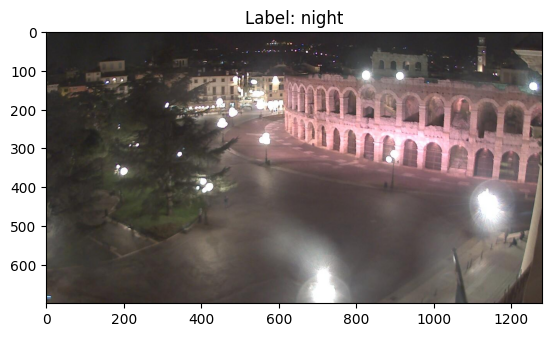

Shape	: (700, 1280, 3)
Label	: night


In [ ]:
random_img_viz(train_img)

## **Langkah 3 - Pra Pengolahan Data**

In [ ]:
def standarized_input(image):
    # resize ke w: 1100, h: 600
    std_img = cv2.resize(image, (1100, 600))

    return std_img

In [ ]:
def label_encoder(label):
    # day = 1; night = 0
    num_val = 0

    if label == 'day':
        num_val = 1

    return num_val

In [ ]:
def preprocess(img_list):
    std_img_list = []

    for item in img_list:
        image = item[0]
        label = item[1]

        std_img = standarized_input(image)
        img_label = label_encoder(label)

        std_img_list.append((std_img, img_label))

    return std_img_list

In [ ]:
train_std_img_list = preprocess(train_img)

In [ ]:
pick_random = np.random.randint(0, len(train_std_img_list))

print(f'Image {pick_random}')
print(train_std_img_list[pick_random][0].shape)

Image 217
(600, 1100, 3)


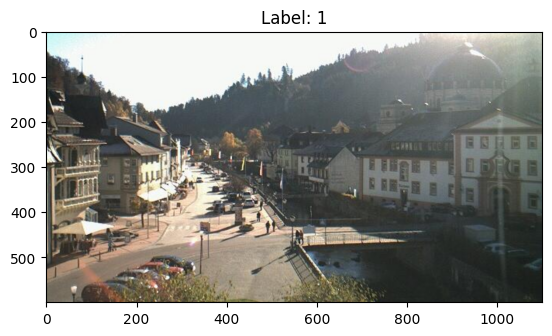

Shape	: (600, 1100, 3)
Label	: 1


In [ ]:
random_img_viz(train_std_img_list)

## **Langkah 4 - Ekstraksi Fitur**

In [ ]:
def avg_brightness(image):
    # ubah ke HSV
    img_hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)

    # rata-rata kecerahan (channel V)
    sum_brightness = np.sum(img_hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    avg = sum_brightness / area

    return avg

Image 23
Avg Brightness: 99.6795


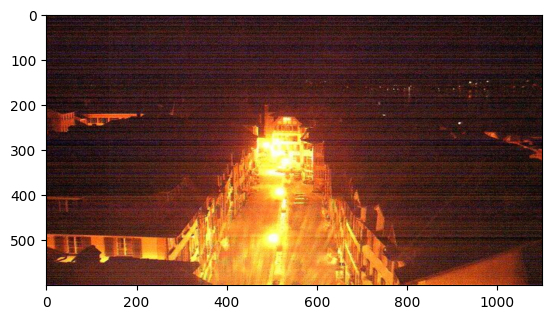

In [ ]:
rand_img = np.random.randint(0, len(train_std_img_list))

feature_img = train_std_img_list[rand_img][0]

avg_img = avg_brightness(feature_img)

print(f'Image {rand_img}')
print(f'Avg Brightness: {avg_img:.4f}')
plt.imshow(feature_img)
plt.show()

## **Langkah 5 - Klasifikasi dengan Metode Threshold**

In [ ]:
def predict_label(img, threshold):
    avg = avg_brightness(img)
    pred = 0

    if avg > threshold:
        pred = 1

    return pred

Image 190
Actual label: 1
Predicted label: 0


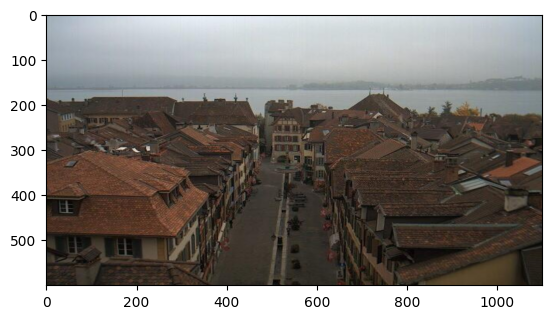

In [ ]:
rand_img = np.random.randint(0, len(train_std_img_list))

pred = predict_label(train_std_img_list[rand_img][0], threshold=120)

print(f'Image {rand_img}')
print(f'Actual label: {train_std_img_list[rand_img][1]}')
print(f'Predicted label: {pred}')
plt.imshow(train_std_img_list[rand_img][0])
plt.show()

## Langkah 6 - Evaluasi Manual

In [ ]:
def evaluate(img_list, threshold):
    miss_labels = []

    for file in img_list:
        img = file[0]
        label = file[1]

        pred_label = predict_label(img, threshold)

        if pred_label != label:
            miss_labels.append((img, pred_label, label))

    total_img = len(img_list)
    corr_pred = total_img - len(miss_labels)
    accuracy = corr_pred / total_img

    print(f'Accuracy: {accuracy:.4f}')

In [ ]:
evaluate(train_std_img_list, threshold=120)

Accuracy: 0.8417


In [ ]:
test_img = load_dataset(test_dir)
test_std_img_list = preprocess(test_img)
evaluate(test_std_img_list, threshold=120)

Accuracy: 0.8688


## Klasifikasi dengan SVM
### Langkah 4 Alternatif - Membuat Feature Vectors

In [ ]:
def extract_avg_bright_feature(img_list):
    avg_list = []
    labels = []

    for img in img_list:
        img_avg = avg_brightness(img[0])
        img_label = img[1]

        avg_list.append(img_avg)
        labels.append(img_label)

    data = np.column_stack((avg_list, labels))
    df = pd.DataFrame(data, columns=['AVG_BRIGHT', 'LABELS'])

    return df

In [ ]:
train_avg_img = extract_avg_bright_feature(train_std_img_list)
print(f'Shape: {train_avg_img.shape}')
train_avg_img.head()

Shape: (240, 2)


,AVG_BRIGHT,LABELS
0,26.946276,0.0
1,114.386045,0.0
2,36.167309,0.0
3,89.905798,0.0
4,48.713038,0.0


In [ ]:
test_avg_img = extract_avg_bright_feature(test_std_img_list)
print(f'Shape: {test_avg_img.shape}')
test_avg_img.head()

Shape: (160, 2)


,AVG_BRIGHT,LABELS
0,37.642245,0.0
1,38.777894,0.0
2,26.358703,0.0
3,41.211485,0.0
4,53.467780,0.0


### Langkah 5 - Buat Model SVM

In [ ]:
from sklearn.svm import SVC

X_train = train_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_train = train_avg_img.iloc[:, 1]
X_test = test_avg_img.iloc[:, 0].values.reshape(-1, 1)
y_test = test_avg_img.iloc[:, 1]

model = SVC()
model.fit(X_train, y_train)

SVC()

### Langkah 6 - Evaluasi

In [ ]:
from sklearn.metrics import accuracy_score

y_train_pred = model.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = model.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'Accuracy on train: {acc_train}')
print(f'Accuracy on test: {acc_test}')

Accuracy on train: 0.8583333333333333
Accuracy on test: 0.9
